Detecção de Fraudes em transações

Entendendo o Desafio


Agora é a sua hora de praticar, aprender fazendo e treinar modelos que detectam fraude em transações reais de cartão de crédito, um problema em que a fraude é rara e a acurácia engana.


Nas Aulas, a Expert Isadora percorre o pipeline inteiro num notebook em Python, da coleta dos dados à explicação do modelo, comparando algoritmos pelas métricas que importam em fraude. O link do dataset aparece na Aula 1: confira lá antes de começar.

O Que Criar


Um notebook que carrega o dataset, trata o desbalanceamento, treina e compara modelos e explica o que levou uma transação a ser marcada como fraude. A base traz as colunas Time, Amount e Class, além das variáveis V1 a V28, transformadas por PCA para proteger a privacidade.



O ponto central é o desbalanceamento: 99,8% das transações são normais e só 0,17% são fraude. Um modelo que responde "não é fraude" para tudo acerta quase sempre e não serve para nada, por isso o foco sai da acurácia e vai para recall, precisão e F1.

Como Fazer


Não existe repositório base. Você monta o seu notebook do zero, seguindo o caminho da Expert:

Explore. Carregue a base com o pandas, entenda as colunas e meça a proporção de fraudes;
Prepare. Crie variáveis novas, como o log do valor, padronize com o StandardScaler e separe treino e teste com stratify, para manter a proporção de fraudes nos dois;
Treine. Comece pela regressão logística como baseline e compare com Random Forest e XGBoost, usando o peso das classes e o ajuste do limiar de decisão;
Avalie. Leia o relatório de classificação, a curva ROC e a curva de precisão e recall, com o recall da fraude como métrica principal;
Explique. Veja a importância das variáveis e use o SHAP para mostrar o que pesou em cada decisão.
As ferramentas vêm do scikit-learn, com o NumPy nas transformações. Undersampling e oversampling entram como alternativas para equilibrar as classes, e para escolher entre os dois vale a regra da Expert: teste.

Ideias para Evoluir


Testar undersampling e oversampling e comparar o recall de cada um;
Levar o Random Forest para o pipeline com ajuste de limiar, como a Expert sugere;


Ampliar a busca de hiperparâmetros do GridSearchCV;


Criar variáveis de comportamento ao longo do tempo, como transações em sequência;


Testar outros modelos de classificação e comparar todos pelo recall.


Se você ainda está começando, tudo bem. Um modelo simples, com as métricas certas e bem explicadas, vale mais que cinco algoritmos comparados só pela acurácia.

Uma Ajuda durante o Caminho
Quando as métricas parecerem boas demais, o DIO Agent ajuda a interpretar:

Estou treinando modelos para detectar fraude em cartão,
com uma base em que só 0,17% das transações são fraude.

Me ajude a entender por que a acurácia engana aqui e
como ler recall, precisão e F1 para a classe de fraude.

Importante: não quero uma resposta pronta para copiar.
Quero entender o processo e construir a minha.


O Que Entregar


Suba o notebook para um repositório público na sua conta do GitHub. No README.md, explique:


O problema, e por que o desbalanceamento muda a forma de avaliar;
O que você fez na preparação dos dados;


A comparação entre os modelos, com recall, precisão e F1 da classe de fraude;


O limiar de decisão escolhido e o que o SHAP mostrou;
O que você mudou em relação ao que a Expert fez.
Deixe as saídas salvas no notebook, com as tabelas e as curvas. Evidência de que o modelo roda é o que mais pesa em um portfólio.

Antes de submeter, confira:

O notebook roda do início ao fim, sem célula quebrada;


O dataset é carregado pelo link, como no vídeo, e não fica no repositório;
Todo arquivo citado no README existe e tem conteúdo;
O link enviado é o do repositório, não o de um arquivo dentro dele;
O repositório está na sua conta e público;
O nome do repositório ficou legível, em minúsculas e sem acento.

Resultado Esperado


Ao final, você terá um projeto de detecção de fraude com dados reais, do tratamento à explicação do modelo. O repositório mostra o que mais conta nessa área: escolher a métrica certa para um problema desbalanceado e justificar cada decisão do modelo.

Bons estudos e bom projeto 🚀

In [1]:
import pandas as pd

In [2]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**Problema de classificação desbalanceada**

0 - transações normais

1 - Fraudes

In [3]:
df['Class'].value_counts(normalize=True)

,proportion
Class,
0,0.998273
1,0.001727


**Feature Engineering**

In [4]:
import numpy as np

In [10]:
df["Amount_log"] = np.log1p(df['Amount'])

**Padronização**

sklearn (ajusta os dados para uma escala comum):

média = 0

desvio padrão = 1

recall: qtas fraudes encontrou

precision: o q o modelo encontrou como fraude se realmente é fraude

In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
scaler = StandardScaler()

In [13]:
df['Amount_scaler'] = scaler.fit_transform(df[['Amount']])

In [14]:
from sklearn.model_selection import train_test_split

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

**Logistic Regression**

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [16]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.66      0.73       148

    accuracy                           1.00     85443
   macro avg       0.92      0.83      0.87     85443
weighted avg       1.00      1.00      1.00     85443



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [17]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

AUC: 0.9272042339543365


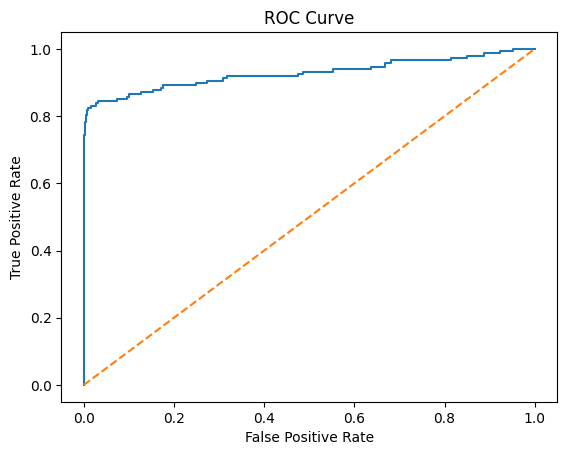

In [18]:
y_pred_proba = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show

print("AUC:", roc_auc_score(y_test, y_pred_proba))

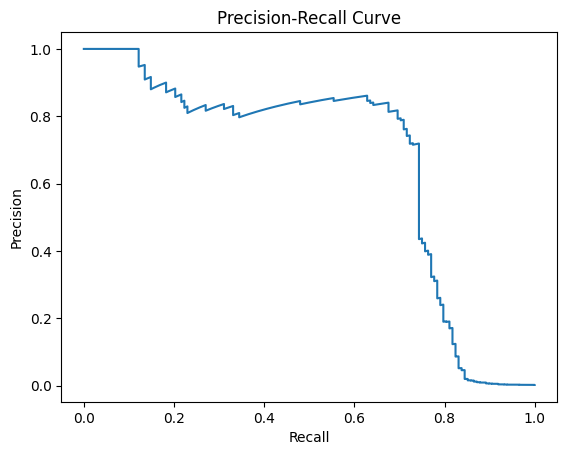

In [19]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)

plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

**Balanceamento de Dados**

In [20]:
# Undersampling
fraudes = df[df['Class'] == 1]
normais = df[df['Class'] == 0].sample(n=len(fraudes), random_state=42)

df_under = pd.concat([fraudes, normais])


In [22]:
# Oversampling
from imblearn.over_sampling import SMOTE

smote = SMOTE()

# Aplicando o SMOTE nos dados
X_res, y_res = smote.fit_resample(X, y)

df_over = pd.concat([X_res, y_res], axis=1)

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=50, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=42)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.76      0.79       148

    accuracy                           1.00     85443
   macro avg       0.92      0.88      0.90     85443
weighted avg       1.00      1.00      1.00     85443



In [26]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)

y_prob = pipeline.predict(X_test)

In [27]:
thresholds = 0.3

y_prod_custom = (y_pred >= thresholds).astype(int)

print(classification_report(y_test, y_prod_custom))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.86      0.61      0.72       148

    accuracy                           1.00     85443
   macro avg       0.93      0.81      0.86     85443
weighted avg       1.00      1.00      1.00     85443



**Modelo Avançado - XGBoost**

In [28]:
from xgboost import XGBClassifier

xgb = XGBClassifier(scale_pos_weight = 10, use_label_encoder=False, eval_metric="logloss")

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:14:48] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [30]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



**Importância das Variáveis**

Ajuda a entender quais variáveis influenciam mais o modelo

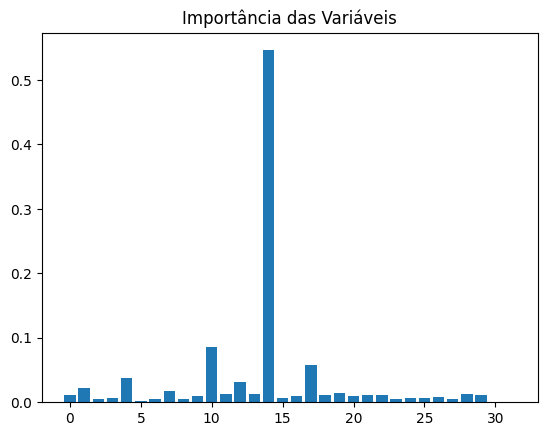

In [33]:
import matplotlib.pyplot as plt

importancias = xgb.feature_importances_

plt.bar(range(len(importancias)), importancias)
plt.title('Importância das Variáveis')
plt.show()

**Ajuste de hiperparâmetros**

Testa-se várias combinações para melhorar o modelo

In [34]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5]
}

grid = GridSearchCV(XGBClassifier(eval_metric="logloss"), param_grid, cv=3, scoring="recall")

grid.fit(X_train, y_train)

print("Melhor modelo:",grid.best_params_)

Melhor modelo: {'max_depth': 5, 'n_estimators': 100}


**Explicabilidade (SHAP)**

SHAP mostra como cada variável influencia a decisão do modelo

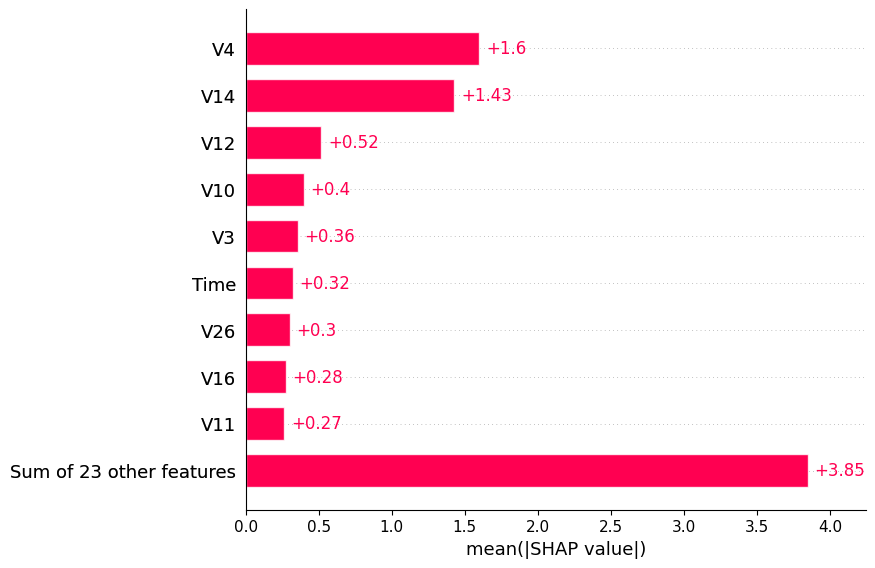

In [37]:
# Instala a biblioteca SHAP caso ela não esteja presente
!pip install -q shap

import shap

# Inicializa e calcula os valores SHAP para o modelo XGBoost
explainer = shap.Explainer(xgb)
shap_values = explainer(X_test[:100])

# Gera o gráfico de cascata (waterfall plot)
shap.plots.bar(shap_values)